In [49]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import (
    deeplabv3_resnet50
)

from torchvision.models.segmentation import (
    lraspp_mobilenet_v3_large
)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [119]:
TRAIN_IMG_DIR = r"/content/dataset/dataset/train/img"
TRAIN_LABEL_DIR = r"/content/dataset/dataset/train/label"

In [120]:
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 512

BATCH_SIZE = 2

NUM_CLASSES = 34

In [121]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor(),
])

mask_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_HEIGHT, IMAGE_WIDTH),
        interpolation=Image.NEAREST
    )
])

In [122]:
class CityscapesDataset(Dataset):

    def __init__(
        self,
        img_dir,
        label_dir,
        image_transform=None,
        mask_transform=None
    ):

        self.img_dir = img_dir
        self.label_dir = label_dir

        self.image_transform = image_transform
        self.mask_transform = mask_transform

        self.image_files = sorted(os.listdir(img_dir))
        self.label_files = sorted(os.listdir(label_dir))

    def __len__(self):

        return len(self.image_files)

    def __getitem__(self, idx):

      image_path = os.path.join(
          self.img_dir,
          self.image_files[idx]
      )

      label_path = os.path.join(
          self.label_dir,
          self.label_files[idx]
      )

      image = Image.open(image_path).convert("RGB")

      mask = Image.open(label_path)

      if self.image_transform:
          image = self.image_transform(image)

      if self.mask_transform:
          mask = self.mask_transform(mask)

      mask = np.array(mask)

      # If RGB mask, take first channel
      if len(mask.shape) == 3:
          mask = mask[:, :, 0]

      # LIMIT VALUES SAFELY
      mask = mask % NUM_CLASSES

      mask = torch.tensor(mask, dtype=torch.long)

      return image, mask

In [123]:
train_dataset = CityscapesDataset(
    TRAIN_IMG_DIR,
    TRAIN_LABEL_DIR,
    image_transform=image_transform,
    mask_transform=mask_transform
)

torch.Size([3, 256, 512])
torch.Size([256, 512])


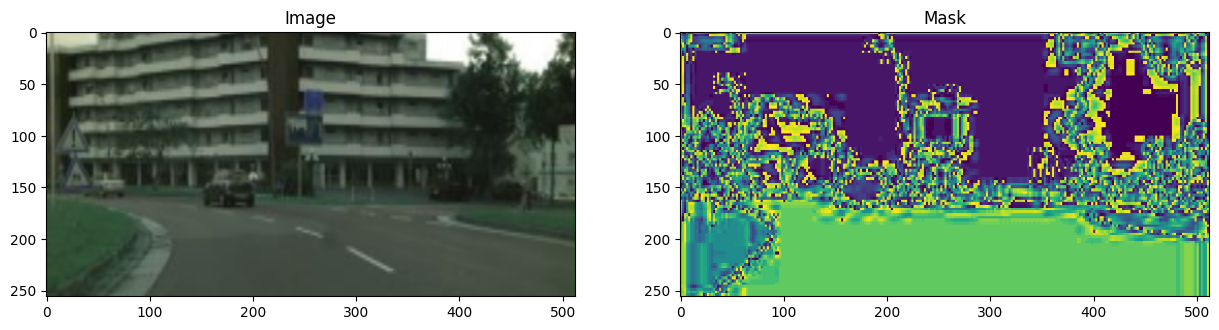

In [124]:
image, mask = train_dataset[0]

print(image.shape)
print(mask.shape)

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("Image")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Mask")

plt.show()

In [125]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [126]:
images, masks = next(iter(train_loader))

print(images.shape)
print(masks.shape)

torch.Size([2, 3, 256, 512])
torch.Size([2, 256, 512])


In [127]:
images = images.to(device)
masks = masks.to(device)

print(images.device)
print(masks.device)

cuda:0
cuda:0


# UNet

In [128]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.conv(x)

In [129]:
class UNet(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # Encoder
        self.down1 = DoubleConv(3, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up1 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.conv_up2 = DoubleConv(128, 64)

        # Final output
        self.final = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        c1 = self.down1(x)
        p1 = self.pool1(c1)

        c2 = self.down2(p1)
        p2 = self.pool2(c2)

        # Bottleneck
        bn = self.bottleneck(p2)

        # Decoder
        u1 = self.up1(bn)

        u1 = torch.cat([u1, c2], dim=1)

        u1 = self.conv_up1(u1)

        u2 = self.up2(u1)

        u2 = torch.cat([u2, c1], dim=1)

        u2 = self.conv_up2(u2)

        outputs = self.final(u2)

        return outputs

In [142]:
unet_model = UNet(num_classes=NUM_CLASSES)

unet_model = unet_model.to(device)

In [143]:
outputs = unet_model(images)

print(outputs.shape)

torch.Size([2, 34, 256, 512])


In [144]:
criterion = nn.CrossEntropyLoss()

In [145]:
print(outputs.shape)
print(masks.shape)

torch.Size([2, 34, 256, 512])
torch.Size([2, 256, 512])


In [146]:
print(torch.min(masks))
print(torch.max(masks))

tensor(0, device='cuda:0')
tensor(33, device='cuda:0')


In [147]:
loss = criterion(outputs, masks)

print(loss.item())

3.535468101501465


In [148]:
optimizer = torch.optim.Adam(
    unet_model.parameters(),
    lr=0.001
)

In [149]:
optimizer.zero_grad()

loss.backward()

optimizer.step()

print("Training step completed")

Training step completed


# Full Training Loop

In [150]:
EPOCHS = 5

for epoch in range(EPOCHS):

    unet_model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = unet_model(images)

        loss = criterion(outputs, masks)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(f"Epoch {epoch+1}/{EPOCHS} Loss: {epoch_loss:.4f}")

Epoch 1/5 Loss: 2.7392
Epoch 2/5 Loss: 2.5133
Epoch 3/5 Loss: 2.4486
Epoch 4/5 Loss: 2.4047
Epoch 5/5 Loss: 2.3750


# Validation

In [25]:
VAL_IMG_DIR = r"/content/dataset/dataset/val/img"
VAL_LABEL_DIR = r"/content/dataset/dataset/val/label"

In [26]:
val_dataset = CityscapesDataset(
    VAL_IMG_DIR,
    VAL_LABEL_DIR,
    image_transform=image_transform,
    mask_transform=mask_transform
)

In [27]:
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [151]:
unet_model.eval()

val_loss = 0.0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = unet_model(images)

        loss = criterion(outputs, masks)

        val_loss += loss.item()

val_loss /= len(val_loader)

In [ ]:
train_loss = running_loss / len(train_loader)

In [153]:
print(
    f"Epoch {epoch+1} | "
    f"Train Loss: {train_loss:.4f} | "
    f"Val Loss: {val_loss:.4f}"
)

Epoch 5 | Train Loss: 2.3750 | Val Loss: 2.3672


In [32]:
torch.save(
    unet_model.state_dict(),
    "unet_cityscapes.pth"
)

In [33]:
unet_model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():

    outputs = unet_model(images)

preds = torch.argmax(outputs, dim=1)

# UNet results

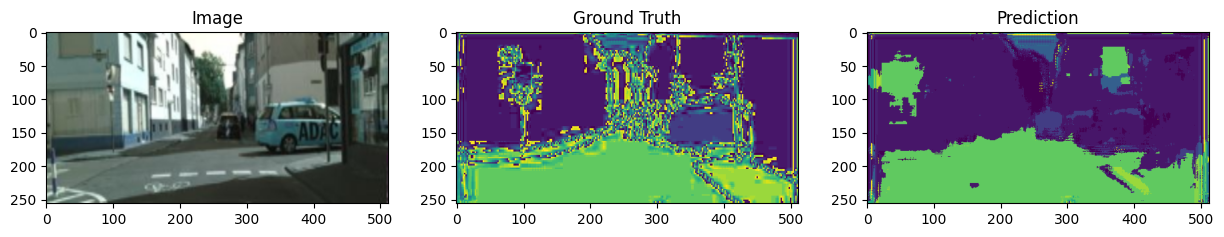

In [34]:
image = images[0].cpu().permute(1,2,0)

gt_mask = masks[0]

pred_mask = preds[0].cpu()

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(gt_mask)
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred_mask)
plt.title("Prediction")

plt.show()

In [83]:
torch.save({
    'model_state_dict': unet_model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'num_classes': NUM_CLASSES
}, 'unet_checkpoint.pth')

print("U-Net saved!")

U-Net saved!


# SegNet

In [35]:
class SegNet(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2, 2)
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                128,
                128,
                kernel_size=2,
                stride=2
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                64,
                64,
                kernel_size=2,
                stride=2
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                64,
                num_classes,
                kernel_size=1
            )
        )

    def forward(self, x):

        x = self.encoder(x)

        x = self.decoder(x)

        return x

In [36]:
segnet_model = SegNet(num_classes=NUM_CLASSES)

segnet_model = segnet_model.to(device)

In [37]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    segnet_model.parameters(),
    lr=0.001
)

In [38]:
EPOCHS = 5

for epoch in range(EPOCHS):

    segnet_model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = segnet_model(images)

        loss = criterion(outputs, masks)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(
        f"SegNet Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {epoch_loss:.4f}"
    )

SegNet Epoch 1/5 Loss: 2.8478
SegNet Epoch 2/5 Loss: 2.6799
SegNet Epoch 3/5 Loss: 2.6343
SegNet Epoch 4/5 Loss: 2.6028
SegNet Epoch 5/5 Loss: 2.5797


In [41]:
model = segnet_model

model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():

    outputs = model(images)

preds = torch.argmax(outputs, dim=1)

# SegNet results

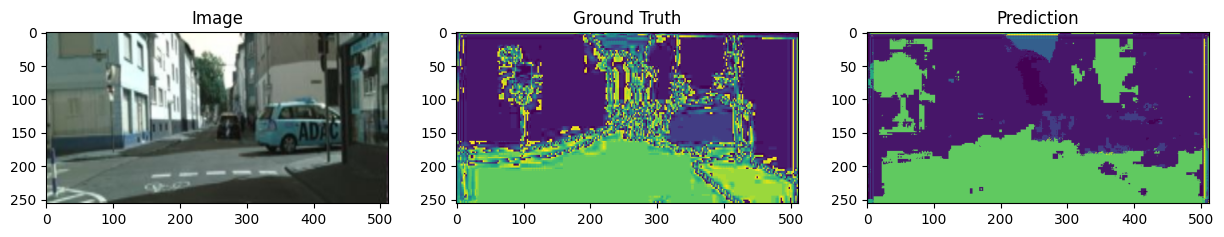

In [42]:
image = images[0].cpu().permute(1,2,0)

gt_mask = masks[0]

pred_mask = preds[0].cpu()

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(gt_mask)
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred_mask)
plt.title("Prediction")

plt.show()

In [84]:
torch.save({
    'model_state_dict': segnet_model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'num_classes': NUM_CLASSES
}, 'segnet_checkpoint.pth')

print("SegNet saved!")

SegNet saved!


# MobileNet V3 Large

In [50]:
mobilenet_model = lraspp_mobilenet_v3_large(
    weights=None,
    num_classes=NUM_CLASSES
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 99.5MB/s]


In [51]:
mobilenet_model = mobilenet_model.to(device)

In [52]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mobilenet_model.parameters(),
    lr=0.001
)

In [56]:
EPOCHS = 10

for epoch in range(EPOCHS):

    mobilenet_model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = mobilenet_model(images)["out"]

        loss = criterion(outputs, masks)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(
        f"MobileNet Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {epoch_loss:.4f}"
    )

MobileNet Epoch 1/10 Loss: 2.1255
MobileNet Epoch 2/10 Loss: 2.1140
MobileNet Epoch 3/10 Loss: 2.0932
MobileNet Epoch 4/10 Loss: 2.0900
MobileNet Epoch 5/10 Loss: 2.0766
MobileNet Epoch 6/10 Loss: 2.0678
MobileNet Epoch 7/10 Loss: 2.0629
MobileNet Epoch 8/10 Loss: 2.0558
MobileNet Epoch 9/10 Loss: 2.0457
MobileNet Epoch 10/10 Loss: 2.0354


In [57]:
mobilenet_model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():

    outputs = mobilenet_model(images)["out"]

preds = torch.argmax(outputs, dim=1)

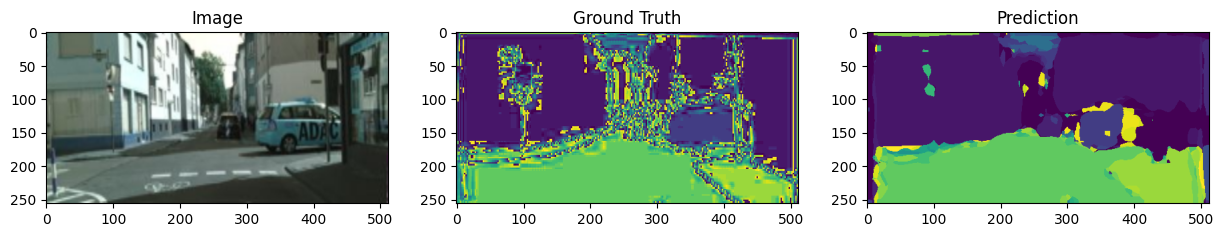

In [58]:
image = images[0].cpu().permute(1,2,0)

gt_mask = masks[0]

pred_mask = preds[0].cpu()

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(gt_mask)
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred_mask)
plt.title("Prediction")

plt.show()

In [85]:
torch.save({
    'model_state_dict': mobilenet_model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'num_classes': NUM_CLASSES
}, 'mobilenet_checkpoint.pth')

print("MobileNet saved!")

MobileNet saved!


# FRRU Block

In [59]:
class FRRU(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x):

        residual = x

        x = self.conv1(x)
        x = self.relu(x)

        x = self.conv2(x)

        x = x + residual

        x = self.relu(x)

        return x

In [60]:
class SimpleFRRN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.initial = nn.Sequential(

            nn.Conv2d(3, 64, 3, padding=1),

            nn.ReLU(inplace=True)
        )

        self.frru1 = FRRU(64, 64)

        self.pool1 = nn.MaxPool2d(2)

        self.frru2 = FRRU(64, 64)

        self.up1 = nn.ConvTranspose2d(
            64,
            64,
            kernel_size=2,
            stride=2
        )

        self.final = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        x = self.initial(x)

        x = self.frru1(x)

        x = self.pool1(x)

        x = self.frru2(x)

        x = self.up1(x)

        x = self.final(x)

        return x

In [61]:
frrn_model = SimpleFRRN(
    num_classes=NUM_CLASSES
)

frrn_model = frrn_model.to(device)

In [62]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    frrn_model.parameters(),
    lr=0.001
)

In [67]:
EPOCHS = 10

for epoch in range(EPOCHS):

    frrn_model.train()

    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = frrn_model(images)

        loss = criterion(outputs, masks)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(
        f"FRRN Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {epoch_loss:.4f}"
    )

FRRN Epoch 1/10 Loss: 2.6115
FRRN Epoch 2/10 Loss: 2.5996
FRRN Epoch 3/10 Loss: 2.5902
FRRN Epoch 4/10 Loss: 2.5821
FRRN Epoch 5/10 Loss: 2.5770
FRRN Epoch 6/10 Loss: 2.5723
FRRN Epoch 7/10 Loss: 2.5681
FRRN Epoch 8/10 Loss: 2.5629
FRRN Epoch 9/10 Loss: 2.5616
FRRN Epoch 10/10 Loss: 2.5576


In [68]:
frrn_model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():

    outputs = frrn_model(images)

preds = torch.argmax(outputs, dim=1)

In [69]:
print(outputs.shape)
print(preds.shape)

torch.Size([2, 34, 256, 512])
torch.Size([2, 256, 512])


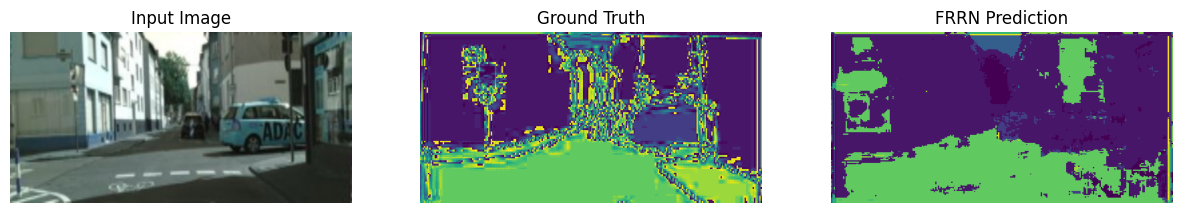

In [70]:
image = images[0].cpu().permute(1, 2, 0)

gt_mask = masks[0]

pred_mask = preds[0].cpu()

plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")

# Ground truth mask
plt.subplot(1, 3, 2)
plt.imshow(gt_mask)
plt.title("Ground Truth")
plt.axis("off")

# Predicted mask
plt.subplot(1, 3, 3)
plt.imshow(pred_mask)
plt.title("FRRN Prediction")
plt.axis("off")

plt.show()

In [86]:
torch.save({
    'model_state_dict': frrn_model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'num_classes': NUM_CLASSES
}, 'frrn_checkpoint.pth')

print("FRRN saved!")

FRRN saved!


# Video Output

In [87]:
!apt-get install ffmpeg -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 100 not upgraded.


In [96]:
import cv2
import os
import numpy as np

os.makedirs("predicted_frames", exist_ok=True)

model = frrn_model
model.eval()

for idx in range(100):

    image, mask = val_dataset[idx]

    input_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():

        outputs = model(input_tensor)

        # For DeepLab/MobileNet:
        # outputs = model(input_tensor)["out"]

    preds = torch.argmax(outputs, dim=1)

    pred_mask = preds[0].cpu().numpy()

    original_image = image.permute(1, 2, 0).numpy()

    original_image = (original_image * 255).astype(np.uint8)

    colored_mask = cv2.applyColorMap(
        (pred_mask * 10).astype(np.uint8),
        cv2.COLORMAP_JET
    )

    colored_mask = cv2.cvtColor(
        colored_mask,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original_image,
        0.7,
        colored_mask,
        0.3,
        0
    )

    frame_path = f"predicted_frames/frame_{idx:03d}.png"

    cv2.imwrite(
        frame_path,
        cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
    )

print("Frames generated successfully!")

Frames generated successfully!


In [97]:
import glob

frame_paths = sorted(
    glob.glob("predicted_frames/*.png")
)

frame = cv2.imread(frame_paths[0])

height, width, _ = frame.shape

video = cv2.VideoWriter(
    "frrn_model_segmentation_output.mp4",
    cv2.VideoWriter_fourcc(*'mp4v'),
    10,
    (width, height)
)

for path in frame_paths:

    frame = cv2.imread(path)

    video.write(frame)

video.release()

print("Video saved!")

Video saved!


In [98]:
!ffmpeg -i frrn_model_segmentation_output.mp4 -vcodec libx264 final_output.mp4

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

In [99]:
from IPython.display import Video

Video("final_output.mp4", embed=True)

# Comparative Analysis

In [154]:
import time

def evaluate_model(model, val_loader, criterion):

    model.eval()

    total_loss = 0.0

    correct_pixels = 0
    total_pixels = 0

    total_inference_time = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            start_time = time.time()

            outputs = model(images)

            # torchvision models
            if isinstance(outputs, dict):
                outputs = outputs["out"]

            inference_time = time.time() - start_time

            total_inference_time += inference_time

            loss = criterion(outputs, masks)

            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)

            correct_pixels += (preds == masks).sum().item()

            total_pixels += masks.numel()

    avg_loss = total_loss / len(val_loader)

    pixel_accuracy = correct_pixels / total_pixels

    avg_inference_time = (
        total_inference_time / len(val_loader)
    )

    fps = 1.0 / avg_inference_time

    return {
        "loss": avg_loss,
        "pixel_accuracy": pixel_accuracy,
        "fps": fps,
        "inference_time": avg_inference_time
    }

In [155]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

In [156]:
results = {}

In [157]:
results["U-Net"] = evaluate_model(
    model,
    val_loader,
    criterion
)

results["U-Net"]["params"] = count_parameters(model)

In [158]:
results["SegNet"] = evaluate_model(
    segnet_model,
    val_loader,
    criterion
)

results["SegNet"]["params"] = count_parameters(segnet_model)

In [159]:
results["MobileNet"] = evaluate_model(
    mobilenet_model,
    val_loader,
    criterion
)

results["MobileNet"]["params"] = count_parameters(
    mobilenet_model
)

In [160]:
results["FRRN"] = evaluate_model(
    frrn_model,
    val_loader,
    criterion
)

results["FRRN"]["params"] = count_parameters(
    frrn_model
)

In [161]:
for model_name, metrics in results.items():

    print(f"\nModel: {model_name}")

    print(f"Loss: {metrics['loss']:.4f}")

    print(
        f"Pixel Accuracy: "
        f"{metrics['pixel_accuracy']:.4f}"
    )

    print(f"FPS: {metrics['fps']:.2f}")

    print(
        f"Inference Time: "
        f"{metrics['inference_time']:.4f} sec"
    )

    print(
        f"Parameters: "
        f"{metrics['params']:,}"
    )


Model: U-Net
Loss: 2.5638
Pixel Accuracy: 0.3681
FPS: 1047.12
Inference Time: 0.0010 sec
Parameters: 168,162

Model: SegNet
Loss: 2.6118
Pixel Accuracy: 0.3662
FPS: 767.22
Inference Time: 0.0013 sec
Parameters: 418,274

Model: MobileNet
Loss: 2.2194
Pixel Accuracy: 0.4251
FPS: 103.67
Inference Time: 0.0096 sec
Parameters: 3,223,748

Model: FRRN
Loss: 2.5638
Pixel Accuracy: 0.3681
FPS: 1007.46
Inference Time: 0.0010 sec
Parameters: 168,162


In [162]:
import pandas as pd

comparison_df = pd.DataFrame(results).T

comparison_df

,loss,pixel_accuracy,fps,inference_time,params
U-Net,2.563783,0.368078,1047.124685,0.000955,168162.0
SegNet,2.611782,0.366245,767.217985,0.001303,418274.0
MobileNet,2.219404,0.425079,103.669793,0.009646,3223748.0
FRRN,2.563783,0.368078,1007.456657,0.000993,168162.0


## Accuracy comparison

<Axes: title={'center': 'Pixel Accuracy Comparison'}>

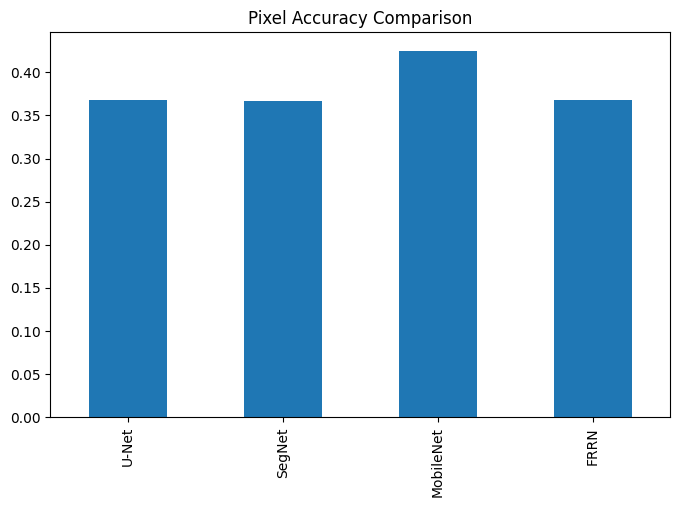

In [163]:
comparison_df["pixel_accuracy"].plot.bar(
    figsize=(8,5),
    title="Pixel Accuracy Comparison"
)

## FPS Comparison

<Axes: title={'center': 'Inference Speed (FPS)'}>

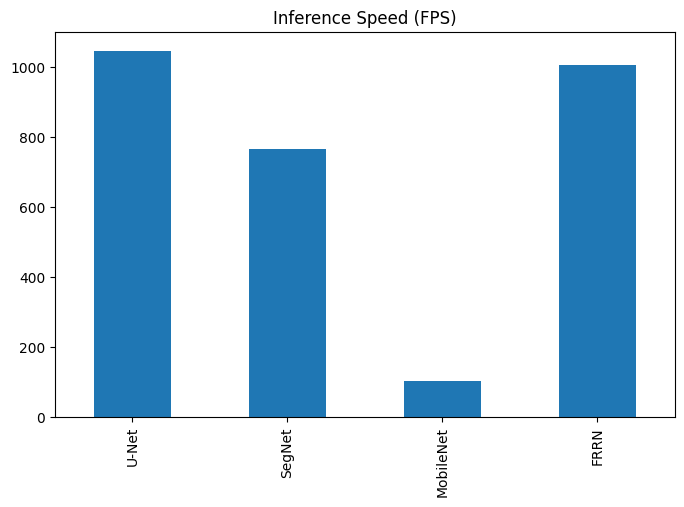

In [164]:
comparison_df["fps"].plot.bar(
    figsize=(8,5),
    title="Inference Speed (FPS)"
)

## FPS Comparison

<Axes: title={'center': 'Inference Speed (FPS)'}>

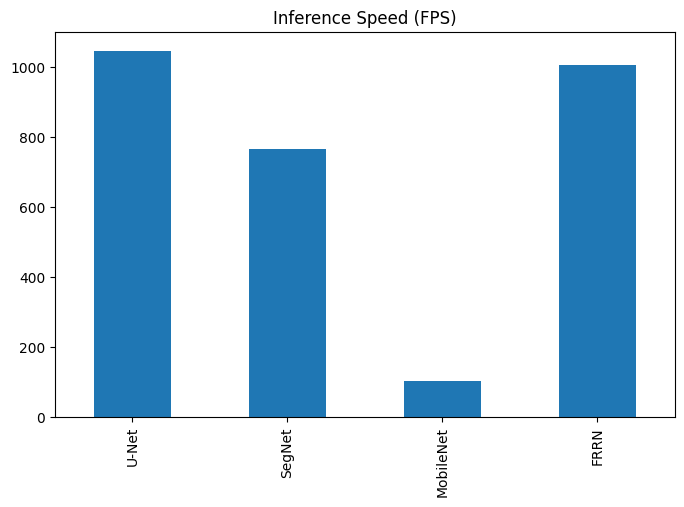

In [165]:
comparison_df["fps"].plot.bar(
    figsize=(8,5),
    title="Inference Speed (FPS)"
)

## Parameter Count Comparison

<Axes: title={'center': 'Model Complexity'}>

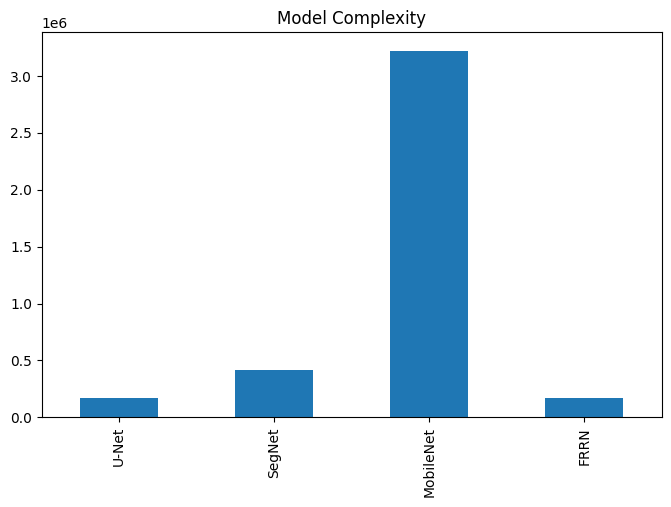

In [166]:
comparison_df["params"].plot.bar(
    figsize=(8,5),
    title="Model Complexity"
)

In [167]:
image, mask = val_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

In [168]:
def get_prediction(model, input_tensor):

    model.eval()

    with torch.no_grad():

        outputs = model(input_tensor)

        if isinstance(outputs, dict):
            outputs = outputs["out"]

    preds = torch.argmax(outputs, dim=1)

    return preds[0].cpu()

In [169]:
unet_pred = get_prediction(model, input_tensor)

segnet_pred = get_prediction(
    segnet_model,
    input_tensor
)

mobilenet_pred = get_prediction(
    mobilenet_model,
    input_tensor
)

frrn_pred = get_prediction(
    frrn_model,
    input_tensor
)

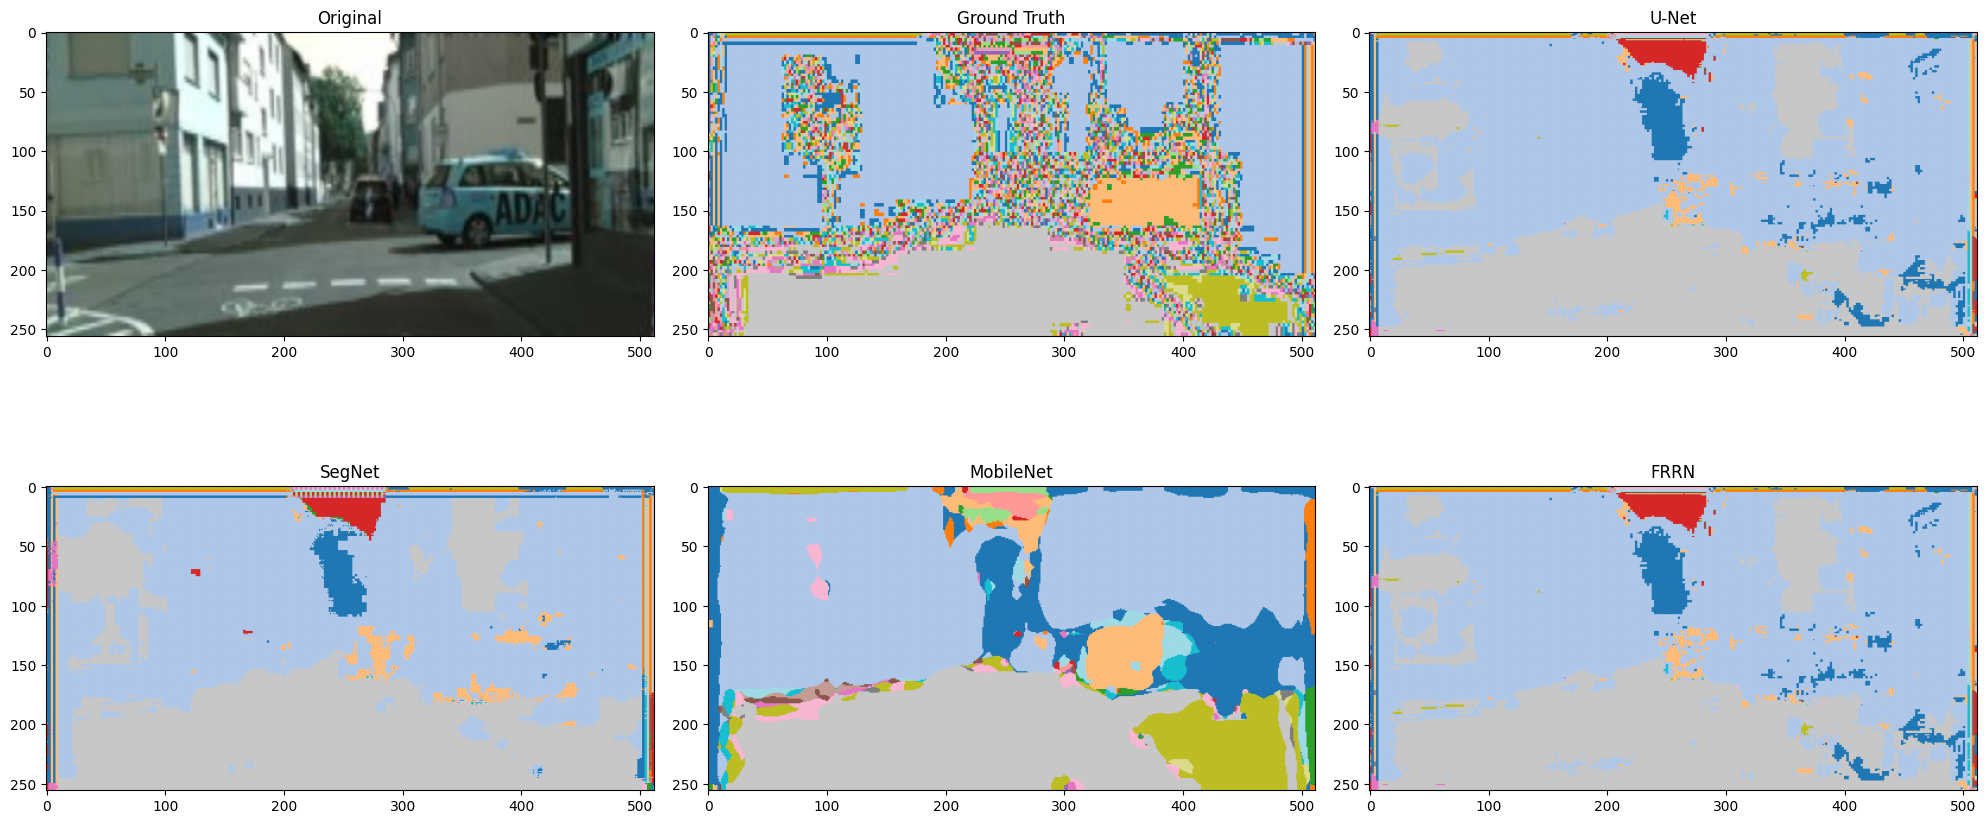

In [170]:
plt.figure(figsize=(20,10))

plt.subplot(2,3,1)
plt.imshow(image.permute(1,2,0))
plt.title("Original")

plt.subplot(2,3,2)
plt.imshow(mask, cmap="tab20")
plt.title("Ground Truth")

plt.subplot(2,3,3)
plt.imshow(unet_pred, cmap="tab20")
plt.title("U-Net")

plt.subplot(2,3,4)
plt.imshow(segnet_pred, cmap="tab20")
plt.title("SegNet")

plt.subplot(2,3,5)
plt.imshow(mobilenet_pred, cmap="tab20")
plt.title("MobileNet")

plt.subplot(2,3,6)
plt.imshow(frrn_pred, cmap="tab20")
plt.title("FRRN")

plt.tight_layout()

plt.show()

## IoU Metric

In [176]:
print(preds.shape)
print(masks.shape)

torch.Size([1, 256, 512])
torch.Size([2, 256, 512])


In [177]:
preds = preds[:masks.shape[0]]

In [178]:
import torch.nn.functional as F

def compute_iou(preds, masks, num_classes):

    # Match batch sizes
    batch_size = min(
        preds.shape[0],
        masks.shape[0]
    )

    preds = preds[:batch_size]
    masks = masks[:batch_size]

    # Match spatial sizes
    if preds.shape[-2:] != masks.shape[-2:]:

        preds = F.interpolate(
            preds.unsqueeze(1).float(),
            size=masks.shape[-2:],
            mode="nearest"
        ).squeeze(1).long()

    ious = []

    preds = preds.reshape(-1)
    masks = masks.reshape(-1)

    for cls in range(num_classes):

        pred_inds = preds == cls
        target_inds = masks == cls

        intersection = (
            pred_inds & target_inds
        ).sum().item()

        union = (
            pred_inds | target_inds
        ).sum().item()

        if union == 0:
            continue

        ious.append(intersection / union)

    if len(ious) == 0:
        return 0.0

    return np.mean(ious)

In [179]:
iou = compute_iou(
    preds,
    masks,
    NUM_CLASSES
)

print("IoU:", iou)

IoU: 0.03078930172615017
